In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("FireGuard libraries imported successfully!")

FireGuard libraries imported successfully!


In [2]:
df = pd.read_csv("fire_risk_synthetic_dataset.csv")

print("Fire Risk Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Fire Risk Dataset Loaded Successfully!
Dataset Shape: (6000, 6)


,temperature_c,humidity_percent,mq4_voltage,rs_kohm,ch4_ppm_approx,label
0,36.29,49.46,1.723,8.672,14.9,Fire_Risk_Low
1,49.24,42.05,2.024,7.314,105.8,Fire_Risk_Medium
2,28.86,60.08,1.726,9.689,1.8,Normal
3,38.73,35.57,1.781,8.605,46.9,Fire_Risk_Low
4,62.97,15.48,1.979,7.356,167.0,Fire_Risk_High


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nFire Risk Class Distribution:")
print(df["label"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   temperature_c     6000 non-null   float64
 1   humidity_percent  6000 non-null   float64
 2   mq4_voltage       6000 non-null   float64
 3   rs_kohm           6000 non-null   float64
 4   ch4_ppm_approx    6000 non-null   float64
 5   label             6000 non-null   str    
dtypes: float64(5), str(1)
memory usage: 353.2 KB

Missing Values:
temperature_c       0
humidity_percent    0
mq4_voltage         0
rs_kohm             0
ch4_ppm_approx      0
label               0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,temperature_c,humidity_percent,mq4_voltage,rs_kohm,ch4_ppm_approx
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,45.164662,45.019825,1.920145,7.356654,116.560750
std,13.862084,14.666480,0.210817,1.590166,103.703555
min,19.630000,5.000000,1.425000,1.267000,0.000000
25%,33.937500,34.947500,1.773000,6.484000,34.000000
50%,42.975000,45.595000,1.880000,7.703500,84.900000
75%,54.830000,55.920000,2.022000,8.507250,168.800000
max,78.260000,83.000000,3.077000,10.000000,425.000000



Fire Risk Class Distribution:
label
Fire_Risk_Low       1500
Fire_Risk_Medium    1500
Normal              1500
Fire_Risk_High      1500
Name: count, dtype: int64


In [4]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Check required columns
required_columns = [
    "temperature_c",
    "humidity_percent",
    "mq4_voltage",
    "rs_kohm",
    "label"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Convert sensor columns to numeric
sensor_columns = [
    "temperature_c",
    "humidity_percent",
    "mq4_voltage",
    "rs_kohm"
]

for col in sensor_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing or invalid values
df = df.dropna(subset=required_columns)

print("Dataset cleaned successfully!")
print("Final Dataset Shape:", df.shape)

Dataset cleaned successfully!
Final Dataset Shape: (6000, 6)


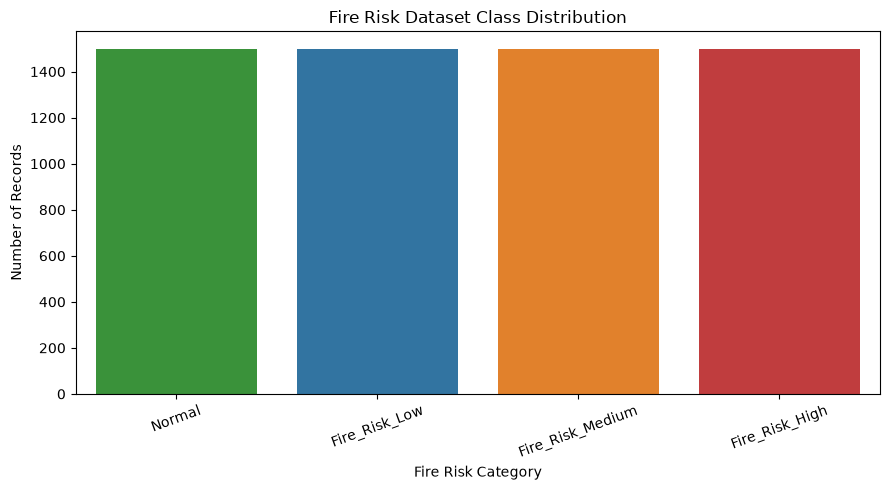

In [5]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=[
        "Normal",
        "Fire_Risk_Low",
        "Fire_Risk_Medium",
        "Fire_Risk_High"
    ],
    legend=False
)

plt.title("Fire Risk Dataset Class Distribution")
plt.xlabel("Fire Risk Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

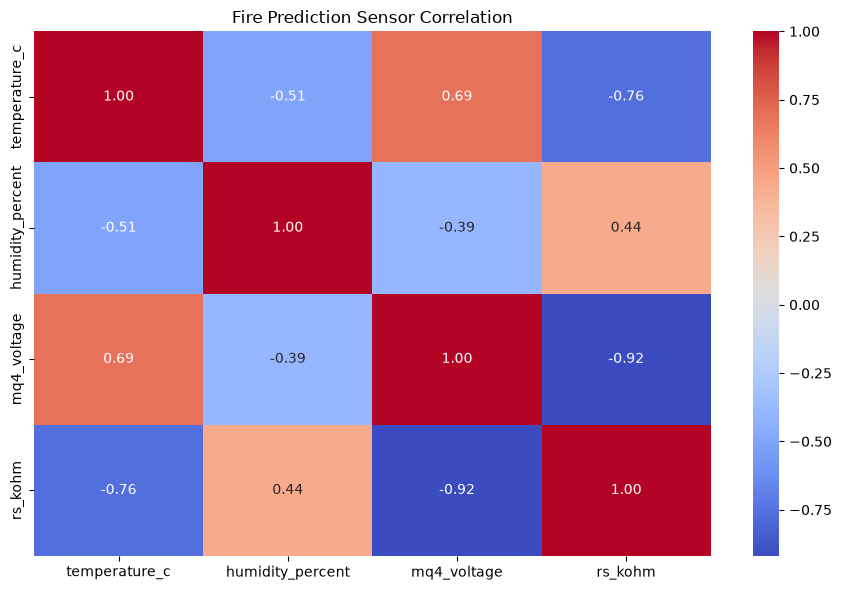

In [6]:
plt.figure(figsize=(9, 6))

correlation = df[sensor_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Fire Prediction Sensor Correlation")
plt.tight_layout()
plt.show()

In [7]:
features = [
    "temperature_c",
    "humidity_percent",
    "mq4_voltage",
    "rs_kohm"
]

target = "label"

X = df[features]
y = df[target]

print("Input Features:")
display(X.head())

print("\nTarget Labels:")
print(sorted(y.unique()))

print("\nTotal Features:", len(features))

Input Features:


,temperature_c,humidity_percent,mq4_voltage,rs_kohm
0,36.29,49.46,1.723,8.672
1,49.24,42.05,2.024,7.314
2,28.86,60.08,1.726,9.689
3,38.73,35.57,1.781,8.605
4,62.97,15.48,1.979,7.356



Target Labels:
['Fire_Risk_High', 'Fire_Risk_Low', 'Fire_Risk_Medium', 'Normal']

Total Features: 4


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Records: 4800
Testing Records: 1200

Training Class Distribution:
label
Fire_Risk_High      1200
Fire_Risk_Medium    1200
Normal              1200
Fire_Risk_Low       1200
Name: count, dtype: int64

Testing Class Distribution:
label
Fire_Risk_Low       300
Fire_Risk_High      300
Fire_Risk_Medium    300
Normal              300
Name: count, dtype: int64


In [9]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Fire Risk Random Forest Model Trained Successfully!")

Fire Risk Random Forest Model Trained Successfully!


In [10]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("FIRE RISK MODEL TEST ACCURACY:")
print(round(accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=model.classes_,
        zero_division=0
    )
)

FIRE RISK MODEL TEST ACCURACY:
89.92 %

CLASSIFICATION REPORT:
                  precision    recall  f1-score   support

  Fire_Risk_High       0.96      0.97      0.96       300
   Fire_Risk_Low       0.83      0.84      0.84       300
Fire_Risk_Medium       0.89      0.86      0.87       300
          Normal       0.92      0.93      0.92       300

        accuracy                           0.90      1200
       macro avg       0.90      0.90      0.90      1200
    weighted avg       0.90      0.90      0.90      1200



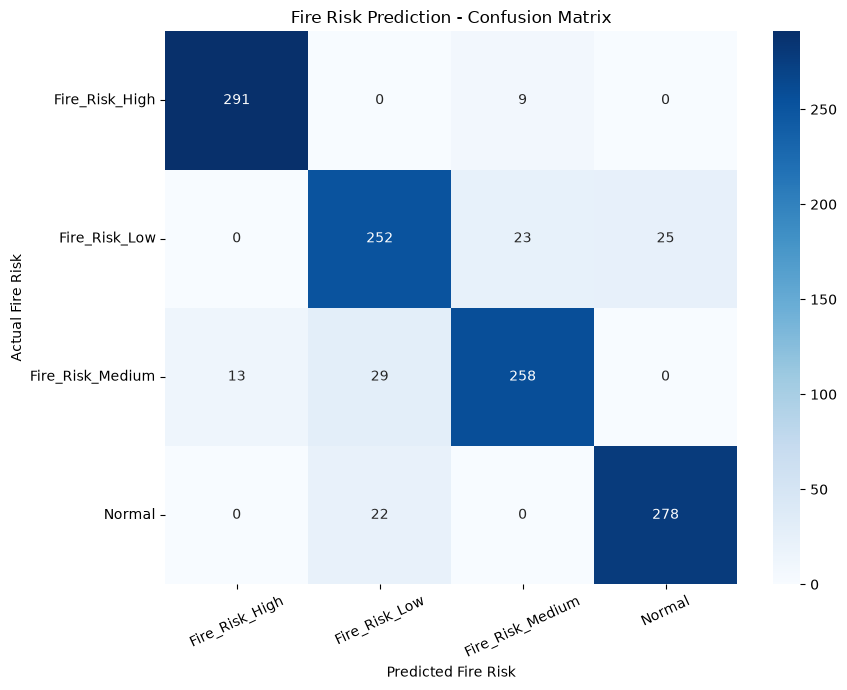

In [11]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Fire Risk")
plt.ylabel("Actual Fire Risk")
plt.title("Fire Risk Prediction - Confusion Matrix")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Fire Prediction Feature Importance:


,Feature,Importance
0,temperature_c,0.712248
3,rs_kohm,0.166858
2,mq4_voltage,0.072595
1,humidity_percent,0.048298


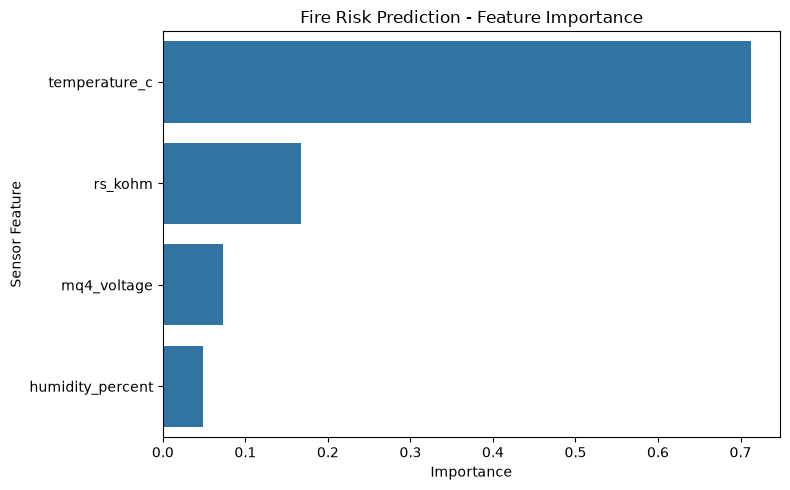

In [12]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Fire Prediction Feature Importance:")
display(importance)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Fire Risk Prediction - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Sensor Feature")
plt.tight_layout()
plt.show()

In [13]:
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross Validation Scores:")
print(cv_scores)

print("\nAverage Cross Validation Accuracy:")
print(round(cv_scores.mean() * 100, 2), "%")

print("\nStandard Deviation:")
print(round(cv_scores.std() * 100, 2), "%")

Cross Validation Scores:
[0.90333333 0.9        0.905      0.91916667 0.92166667]

Average Cross Validation Accuracy:
90.98 %

Standard Deviation:
0.88 %


In [14]:
model_data = {
    "model": model,
    "features": features,
    "classes": list(model.classes_)
}

joblib.dump(
    model_data,
    "fire_risk_model.pkl"
)

print("Fire Risk Model Saved Successfully!")
print("File Name: fire_risk_model.pkl")

Fire Risk Model Saved Successfully!
File Name: fire_risk_model.pkl


In [15]:
loaded_data = joblib.load("fire_risk_model.pkl")

loaded_model = loaded_data["model"]
loaded_features = loaded_data["features"]

print("Saved Fire Risk Model Loaded Successfully!")
print("Model Features:", loaded_features)
print("Model Classes:", loaded_model.classes_)

Saved Fire Risk Model Loaded Successfully!
Model Features: ['temperature_c', 'humidity_percent', 'mq4_voltage', 'rs_kohm']
Model Classes: ['Fire_Risk_High' 'Fire_Risk_Low' 'Fire_Risk_Medium' 'Normal']


In [16]:
sample_reading = pd.DataFrame(
    [[48.0, 35.0, 2.8, 3.5]],
    columns=loaded_features
)

prediction = loaded_model.predict(sample_reading)[0]

probabilities = loaded_model.predict_proba(sample_reading)[0]

print("SAMPLE SENSOR READINGS:")
display(sample_reading)

print("\nPREDICTED FIRE RISK:")
print(prediction)

print("\nMODEL CLASS SCORES:")

for label, probability in zip(
    loaded_model.classes_,
    probabilities
):
    print(f"{label}: {probability * 100:.2f}%")

SAMPLE SENSOR READINGS:


,temperature_c,humidity_percent,mq4_voltage,rs_kohm
0,48.0,35.0,2.8,3.5



PREDICTED FIRE RISK:
Fire_Risk_High

MODEL CLASS SCORES:
Fire_Risk_High: 56.21%
Fire_Risk_Low: 0.00%
Fire_Risk_Medium: 43.79%
Normal: 0.00%


In [17]:
test_readings = pd.DataFrame([
    [28.0, 65.0, 1.7, 9.0],
    [38.0, 50.0, 1.9, 7.5],
    [48.0, 35.0, 2.8, 3.5],
    [62.0, 25.0, 3.0, 2.0]
], columns=loaded_features)

test_predictions = loaded_model.predict(test_readings)

results = test_readings.copy()
results["predicted_fire_risk"] = test_predictions

print("FIRE RISK TEST SCENARIOS:")
display(results)

FIRE RISK TEST SCENARIOS:


,temperature_c,humidity_percent,mq4_voltage,rs_kohm,predicted_fire_risk
0,28.0,65.0,1.7,9.0,Normal
1,38.0,50.0,1.9,7.5,Fire_Risk_Low
2,48.0,35.0,2.8,3.5,Fire_Risk_High
3,62.0,25.0,3.0,2.0,Fire_Risk_High


In [18]:
print("=" * 50)
print("          FIREGUARD MODEL SUMMARY")
print("=" * 50)

print("Model: Random Forest Classifier")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Number of Features:", len(features))
print("Prediction Classes:", list(loaded_model.classes_))
print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Saved Model: fire_risk_model.pkl")

print("=" * 50)
print("FIRE RISK MODEL TRAINING COMPLETED!")
print("=" * 50)

          FIREGUARD MODEL SUMMARY
Model: Random Forest Classifier
Training Records: 4800
Testing Records: 1200
Number of Features: 4
Prediction Classes: ['Fire_Risk_High', 'Fire_Risk_Low', 'Fire_Risk_Medium', 'Normal']
Test Accuracy: 89.92 %
Saved Model: fire_risk_model.pkl
FIRE RISK MODEL TRAINING COMPLETED!
